<a href="https://colab.research.google.com/github/samrat-dhakal-11/CSTAfaSOS/blob/main/CSTAfaSOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CSTAfaSOS**

###Customer Support Triage Assistant for a Small Online Store

In [ ]:
!pip install langchain langgraph langchain-core langchain-community langchain-openai langchain-tavily  openai

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 7.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 5.0 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [langchain-tavily]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from langchain_openai import ChatOpenAI
from langchain_tavily import TavilySearch
from langchain_core.messages import SystemMessage, HumanMessage,AIMessage
from langchain_core.tools import tool
from google.colab import userdata
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.memory import InMemoryStore
from openai import OpenAI

key = userdata.get("OPENAI_API_KEY")
tkey = userdata.get("TAVILY_API_KEY")
gkey = userdata.get("GROQ_API_KEY")
search_tool = TavilySearch(tavily_api_key=tkey, max_results=10,search_depth="advanced")
llm = ChatOpenAI(
    model="gpt-5.4-mini",
    api_key=key
)

client=OpenAI(api_key=key)
checkpointer=InMemorySaver()
from langgraph.graph import START,StateGraph,END,MessagesState
from langgraph.prebuilt import ToolNode,tools_condition
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel,Field

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
order_path="/content/drive/MyDrive/Samrattttt/orders.json"
product_path="/content/drive/MyDrive/Samrattttt/products.json"
policy_path="/content/drive/MyDrive/Samrattttt/policy.md"

In [ ]:
import json
import uuid
from langgraph.graph import START,StateGraph,END,MessagesState
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.types import interrupt,Command
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel,Field
from pathlib import Path

**Customer Support Triage Assistant for a Small Online Store**

###A small shop (clothing, electronics, or a food delivery shop) gets customer messages. The assistant handles them the way a production support system would

Safety check first: abusive or harmful messages are blocked before any agent sees them, the same way your current build works.

Router: sends each message to one of a few agents: order_status (asks for an order ID and looks it up in a local JSON/CSV file), returns_policy (answers from a policy document), product_info (answers from a product catalog), and human_handoff (escalates complaints, refunds over a limit, or anything it can’t answer).

Evaluator with retries: checks that the reply answers the customer’s question, uses only facts from the policy or catalog, and has a polite tone. It retries up to 3 times, then returns the answer with “I couldn’t fully verify this, a support agent will follow up” or hands off to a human.

Checkpointer: keeps each customer’s conversation separate using a thread ID tied to the customer’s account or session.

Why it’s production-like:

Real routing and escalation logic, which is what support teams actually need.
Grounded answers from your own data, so you test for hallucination, not just tone.
A clear human handoff path, which is how real support tools avoid bad automated replies.

Scope for 1–2 days:
Day 1: data files (10 orders, 10 products, one policy page), the router, and the four agents. Use mock data, no real payment or account systems.
Day 2: the evaluator with retries, the handoff path, the checkpointer, and a small test set of 10 messages covering each route plus one refusal and one handoff.


In [ ]:
order=Path(order_path).resolve()
product=Path(product_path).resolve()
policy=Path(policy_path).resolve()
folder=str(policy.parent)
complainf=Path(folder) / "complains.json"
refundf=Path(folder) / "refunds.json"

In [ ]:
""" Order Agent """

@tool
def read_all_orders()->list:
  """ Return every order in shop with all its details."""
  return json.loads(order.read_text(encoding="utf-8"))


@tool
def get_recent_order_info(last_info:int)->list:
  """ Return the latest N orders. Use this when the info of recent orders needed """
  if last_info <= 0:
    return []
  data=json.loads(order.read_text(encoding="utf-8"))
  return data[-last_info:]


@tool
def write_content_file(order_id:str,status:str,item:str)->str:
  """ Write/Append Content(order_id,status,item) to the orders.json file """
  content={'order_id':order_id,'status':status,'item':item}
  data=json.loads(order.read_text(encoding="utf-8"))
  data.append(content)
  with open(order,"w",encoding="utf-8") as f:
    json.dump(data,f,indent=2,ensure_ascii=False)
  return "Order successfully placed."


@tool
def modify_order_info(order_id: str, status: str, item: str = None) -> str:
  """ Update an existing order's status, and its item if the user changed the product. Use this when an order's status or item needs to change. Pass item only if it changed. """
  data = json.loads(order.read_text(encoding="utf-8"))
  for order_row in data:
    if order_row['order_id'] == order_id:
      order_row['status'] = status
      if item is not None:
        order_row['item'] = item
      with open(order, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
      return "Order info modified successfully."
  return f"No order found with ID {order_id}."

ord_agent_tools=[read_all_orders,get_recent_order_info,write_content_file,modify_order_info]

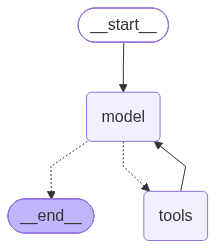

In [ ]:
ord_tool_llm=llm.bind_tools(ord_agent_tools)
ord_tool_node=ToolNode(ord_agent_tools)
def ord_model(state:MessagesState):
  sys_prompt=SystemMessage(content="""
  You are A Order Agent:
  Your Job are:
    - If a user is customer : Then only use write_content_file tool
    - If a user is admin/shop owner :Then he can acess all tools

  Whether The user is whom: But you should reply with proper manner :using polite,helful and engaging sentences
  """)
  messages=[sys_prompt]+state['messages']
  response=ord_tool_llm.invoke(messages)
  return {'messages':[response]}

ord_graph=StateGraph(MessagesState)

ord_graph.add_node("model",ord_model)
ord_graph.add_node("tools",ord_tool_node)


ord_graph.add_edge(START,"model")
ord_graph.add_conditional_edges("model",tools_condition)
ord_graph.add_edge("tools","model")

ord_agent=ord_graph.compile(checkpointer=checkpointer)
ord_agent

In [ ]:
""" Product Agent """

@tool
def read_all_products()->list:
  """ Return every product in shop with all its details."""
  return json.loads(product.read_text(encoding="utf-8"))


@tool
def get_recent_product_info(last_info:int)->list:
  """ Return the latest N products. Use this when the info of recent products needed """
  if last_info <= 0:
    return []
  data=json.loads(product.read_text(encoding="utf-8"))
  return data[-last_info:]


@tool
def write_new_product(name:str,price:float,category:str,stock:int)->str:
  """ Write/Append Content(name,price,category,stock) to the products.json file """

  content={'name':name,'price':price,'category':category,'stock':stock}

  data=json.loads(product.read_text(encoding="utf-8"))
  data.append(content)
  with open(product,"w",encoding="utf-8") as f:
    json.dump(data,f,indent=2,ensure_ascii=False)
  return "Product successfully Added."

@tool
def modify_product_info(name: str, price: float, stock: int) -> str:
  """ Update an existing product's price and its total stock quantity. Use this when a product's price changes or its stock changes after an order. stock is the new total, not the amount sold. """
  data = json.loads(product.read_text(encoding="utf-8"))
  for prod in data:
    if prod['name'] == name:
      prod['price'] = price
      prod['stock'] = stock
      with open(product, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
      return "Product info modified successfully."
  return f"No product found with name {name}."

prod_agent_tools=[read_all_products,get_recent_product_info,write_new_product,modify_product_info]

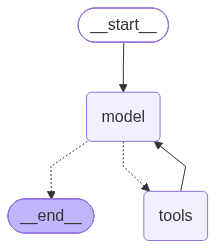

In [ ]:

prod_tool_llm=llm.bind_tools(prod_agent_tools)
prod_tool_node=ToolNode(prod_agent_tools)
def prod_model(state:MessagesState):
  sys_prompt=SystemMessage(content="""
  You are A Product Agent:
  Your Job are:
    - If a user is customer : Then use read_all_products and get_recent_product_info tools
    - If a user is admin/shop owner :Then use  all tools
  Whether The user is whom: But you should reply with proper manner :using polite,helful and engaging sentences
  """)
  messages=[sys_prompt]+state['messages']
  response=prod_tool_llm.invoke(messages)
  return {'messages':[response]}

prod_graph=StateGraph(MessagesState)

prod_graph.add_node("model",prod_model)
prod_graph.add_node("tools",prod_tool_node)


prod_graph.add_edge(START,"model")
prod_graph.add_conditional_edges("model",tools_condition)
prod_graph.add_edge("tools","model")

prod_agent=prod_graph.compile(checkpointer=checkpointer)
prod_agent

In [ ]:
""" Policy Agent """

@tool
def read_policy()->str:
  """ Replace the shop's full policy text with new_policy. Use this only when the owner asks to change the policy."""
  return policy.read_text(encoding="utf-8")

@tool
def update_policy(new_policy)->str:
  """ Updates the new policy of the shop"""
  with open(policy,"w",encoding="utf-8") as f:
    f.write(new_policy)
  return "Shop Policy Updated "

pol_agent_tools=[read_policy,update_policy]

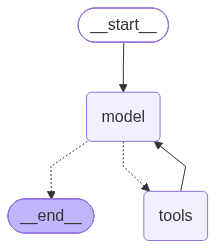

In [ ]:

policy_tool_llm=llm.bind_tools(pol_agent_tools)
policy_tool_node=ToolNode(pol_agent_tools)
def policy_model(state:MessagesState):
  sys_prompt=SystemMessage(content="""
  You are A Human Handoff Agent:
  Your Job are:
    - If a user is customer : Then use only read_policy
    - If a user is admin/shop owner : Then use all 2 tools

  Whether The user is whom: But you should reply with proper manner :using polite,helful and engaging sentences
  """)
  messages=[sys_prompt]+state['messages']
  response=policy_tool_llm.invoke(messages)
  return {'messages':[response]}

policy_graph=StateGraph(MessagesState)

policy_graph.add_node("model",policy_model)
policy_graph.add_node("tools",policy_tool_node)


policy_graph.add_edge(START,"model")
policy_graph.add_conditional_edges("model",tools_condition)
policy_graph.add_edge("tools","model")

pol_agent=policy_graph.compile(checkpointer=checkpointer)
pol_agent

In [ ]:
""" Human Handoff Agent """
@tool
def take_complains_from_users(user_email:str,complain:str)->str:
  """ Revives User Complain and updates on complain file """
  data=json.loads(complainf.read_text(encoding="utf-8"))
  compl={'user_email':user_email,'complain':complain,"status":"pending","reply":""}
  data.append(compl)
  with open(complainf, "w", encoding="utf-8") as f:
    json.dump(data, f, indent=2, ensure_ascii=False)
  return "Complain Submitted"


@tool
def get_all_complains()->list:
  """ Returns all the compains of the user """
  data=json.loads(complainf.read_text(encoding="utf-8"))
  return data


@tool
def update_complains_from_shop_owner(user_email:str,status:str,reply:str)->str:
  """ Updates from shop to complain form user especially changing status and giving reply """
  data=json.loads(complainf.read_text(encoding="utf-8"))
  class Eval_Complain(BaseModel):
    human_need:Literal['yes','no']=Field(...,description="Return yes if Complain  necessarily required human reply else no if you think you think you(llm) can reply this as per shops polices")
  class Reply_w(BaseModel):
    reply_wh:str=Field(...,description="As per the shop policy write the suitable compalin reply for the complain")
  eval_comp_llm=llm.with_structured_output(Eval_Complain)
  reply_writter_llm=llm.with_structured_output(Reply_w)
  shop_policy=policy.read_text(encoding="utf-8")
  for como in data:
    if como['user_email']==user_email:
      reply=eval_comp_llm.invoke(f"Shop Policy->\n{shop_policy} \n User/Customer  Complain ->\n {como["complain"]}")
      if reply.human_need=="no":
        reply=reply_writter_llm.invoke(f"Write a suitable Reply for this on behalf of shop Using shop policy -> \n\n{shop_policy}")
        c_reply=reply.reply_wh

      else:
        msg=interrupt({'agent_msg':f"This is Customer Complain : {como['complain']}\n\n Write a Reply To this Customer:","h_reply":""})
        c_reply=msg["h_reply"]
      como['status']="reviewed"
      como['reply']=c_reply
  with open(complainf, "w", encoding="utf-8") as f:
    json.dump(data, f, indent=2, ensure_ascii=False)
  return "Complain Updated Sucessfully"

hh_agent_tools=[take_complains_from_users,get_all_complains,update_complains_from_shop_owner]

In [ ]:
@tool
def refund_history()

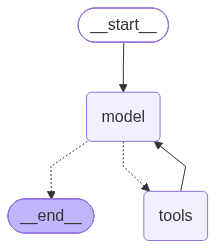

In [ ]:
hh_tool_llm=llm.bind_tools(hh_agent_tools)
hh_tool_node=ToolNode(hh_agent_tools)
def hh_model(state:MessagesState):
  sys_prompt=SystemMessage(content="""
  You are A Human Handoff Agent:
  Your Job are:
    - If a user is customer : Then he can only give complain by giving his email and complain :take_complain_from_users tool else he cannot access tool reply with enter gmail and complain first to complain
    - If a user is admin/shop owner login via email admin@gmail.com or dhakalsamrat111@gmail.com he is accesible to 2 tools:get_all_complains and update_complains_form_shop_owner and so he can ask for all complain or he wanna update the complain

  Whether The user is whom: But you should reply with proper manner :using polite,helful and engaging sentences
  """)
  messages=[sys_prompt]+state['messages']
  response=hh_tool_llm.invoke(messages)
  return {'messages':[response]}

hh_graph=StateGraph(MessagesState)

hh_graph.add_node("model",hh_model)
hh_graph.add_node("tools",hh_tool_node)


hh_graph.add_edge(START,"model")
hh_graph.add_conditional_edges("model",tools_condition)
hh_graph.add_edge("tools","model")

hh_agent=hh_graph.compile(checkpointer=checkpointer)
hh_agent

In [ ]:
while "__intrreput__" in response:
  intrreput_msg=response['__interrupt__'][0].value['agent_msg']
  print(intrreput_msg)
  shop_owner_msg=input("Enter your reply: ")
  response=hh_agent.invoke(Command(resume={'h_reply':shop_owner_msg}),config=config)

print(response['messages'][-1].content)
response['messages'][-1].usage_metadata

In [ ]:
agents=["order_agent","product_agent","policy_agent","hh_agent"]

In [ ]:
class OrcsState(MessagesState):
  user_msg:str
  user_status:str
  user_email:str
  flagged:bool
  next_agent:Literal[*agents]
  ord_a_msg:str
  pord_a_msg:str
  pol_a_msg:str
  hh_a_msg:str
  agent_response:str
  retries:int
  e_status:str



class Router(BaseModel):
  which_agent:Literal[*agents]=Field(...,description="As per user query route to the best suitable agent")
router_llm=llm.with_structured_output(Router)

In [ ]:
or_sp="""

"""

In [ ]:
def safety_evaluator(state:OrcsState):
  """ Guardial  """
  user_query=state.get("messages","")[-1].content
  result=client.moderations.create(model="omni-moderation-latest",input=user_query)
  m_result=result.results[0].flagged
  return {'user_msg':user_query,'flagged':m_result,'retries':0,'e_status':''}

In [ ]:
def next_router_after_safety_check(state:OrcsState)->Literal['router',END]:
  """  If User msg is harmful/unwanted  it route to end else continue """
  if state['flagged']:
    return END
  return "router"

In [ ]:
def router(state:OrcsState):

  return {"next_agent":"hh_agent"}

In [ ]:
def needed_agent(state:OrcsState)->Literal[*agents]:
  return state['next_agent']

In [ ]:
class Response_Evaluator(BaseModel):
  response_quality:Literal['ok',"try_again"]=Field(...,description="As per user qsn  Evalaute Agent Answer and if you think ok then reply ok else try_again ")
agent_response_evaluator=llm.with_structured_output(Response_Evaluator)

def evaluator(state:OrcsState):
  user_query=state['user_msg']
  agent_response=state['agent_response']

  result=client.moderations.create(model="omni-moderation-latest",input=user_query)
  m_result=result.results[0].flagged

  t_retries=state.get('retries',0)+1

  evaluation_result=agent_response_evaluator.invoke(f"User Message ->{user_query}\n\nAgent Response->{agent_response}").response_quality

  if not m_result and evaluation_result=="ok":
    return {'retries':t_retries,'e_status':'ok'}
  if retries >=4:
    return {'retries':t_retries,'e_status':'max_retried'}
  return {'retries':t_retries,'e_status':'try_again'}

In [ ]:
def next_route_after_final_evaluation(state:OrcsState)->Literal[END,"router"]:
  e_status=state.get("e_status","")
  if e_status=="ok" or e_status=="max_retried":
    return END
  else:
    return "router"

In [ ]:
for a in agents:
  print(a)

order_agent
product_agent
policy_agent
hh_agent


In [ ]:
response="This is dummy just sample so give ok in evaluation"
def order_agent(state:OrcsState):
  response=
  return {'agent_response':response}


def product_agent(state:OrcsState):

  return {'agent_response':response}

def policy_agent(state:OrcsState):

  return {'agent_response':response}

def hh_agent(state:OrcsState):

  return {'agent_response':response}

In [ ]:
orcs_graph=StateGraph(OrcsState)

orcs_graph.add_node("safety_check",safety_evaluator)
orcs_graph.add_node("router",router)
orcs_graph.add_node("order_agent",order_agent)
orcs_graph.add_node("product_agent",product_agent)
orcs_graph.add_node("policy_agent",policy_agent)
orcs_graph.add_node("hh_agent",hh_agent)
orcs_graph.add_node("evaluator",evaluator)


orcs_graph.add_edge(START,"safety_check")
orcs_graph.add_conditional_edges("safety_check",next_router_after_safety_check)
orcs_graph.add_conditional_edges("router",needed_agent)
for agent in agents:
  orcs_graph.add_edge(agent,"evaluator")
orcs_graph.add_conditional_edges("evaluator",next_route_after_final_evaluation)

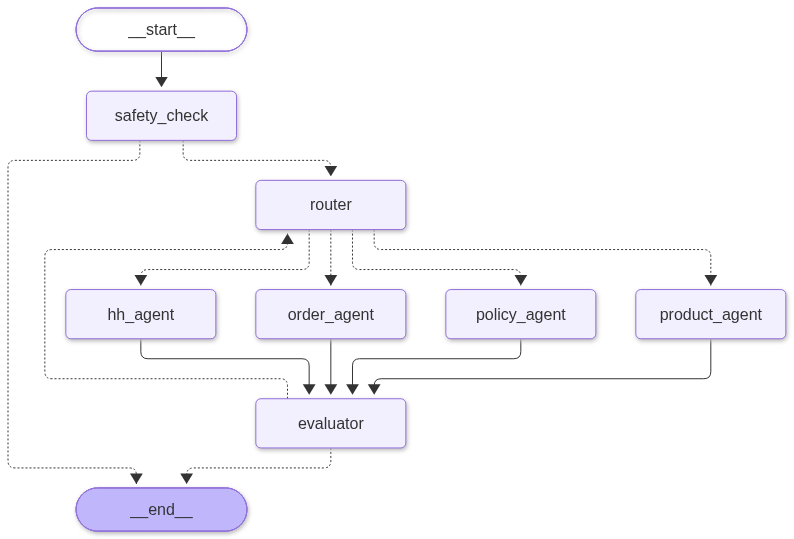

In [ ]:
orcs_agent=orcs_graph.compile(checkpointer=checkpointer)
orcs_agent

In [ ]:
""" Invoking System """

admin_mail=["dhakalsamrat111@gmail.com","admin@gmail.com","admin123@gmail.com"]
user_email=input("Enter your Email: ")
user_msg=input("Enter your message: ")

if user_email in admin_mail:
  status="admin/shop owner"
else:
  status="customer"

id=(user_email+str(uuid.uuid4())).strip()
config={'configuarble':{'thread_id':id}}

msg=[HumanMessage(content=user_msg)]

#response=orcs_agent.invoke('messages':msg,'user_query':user_msg,'user_email':user_email,'user_status':status},config=config)

Enter your Email: H
Enter your message: H
